## arXiv corpus — read this first

This is the **arXiv** twin of the S2ORC notebook, generated by
`accelscan.scripts.make_arxiv_notebooks`. Edit the S2ORC original and regenerate.

Four things make arXiv levels **not** comparable to S2ORC levels:

1. **Self-selected preprints**, skewed to physics and CS, with no peer-review filter.
2. **Raw-LaTeX matching.** The matcher reads the `.tex` source, which includes figure
   captions, spec tables, code listings and `%` comments that GROBID drops from
   S2ORC. This biases any-mention prevalence *upward*; `reported use` and
   model-specific series are better protected because the LLM judges the passage.
3. **No citations.** There is no arXiv→corpusid crosswalk, so §6.4-style citation
   analyses are absent here.
4. **1991–2026 available, 2005–2026 analysed.** 2026 is a partial calendar year:
   fine for shares, marked on counts.

Only **within-corpus trends** should be compared across the two corpora.


# §8 Manufacturer concentration

How concentrated is the hardware science runs on, and is anything eroding it?

* **8.1 Manufacturer shares** over time, by field.
* **8.2 Concentration indices** — HHI and entropy across manufacturers.
* **8.3 CUDA lock-in proxy** — share of accelerator papers whose passages
  mention CUDA vs the portable alternatives (OpenCL/ROCm/SYCL/oneAPI). Software
  lock-in is the mechanism that would keep concentration sticky even if rival
  silicon becomes competitive.
* **8.4 Multi-vendor papers** — do papers ever mix vendors?
* **8.5 Export-control sidebar** — A800/H800/H20, the China-market parts created
  by the 2022/2023 US controls. Their appearance is a natural experiment in how
  fast policy reaches the bench.

**Denominator discipline.** Shares are over papers that name a *specific model*
and report *using* it, so generic "we used a GPU" papers (which carry no
manufacturer information) cannot inflate any vendor. The share of accelerator
papers that are generic-only is plotted first, since a falling unknown share can
mechanically manufacture apparent growth.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from accelscan.config import BUCKET, OUT_PREFIX
from accelscan.normalize import canonicalize_column
from accelscan.registry import load_registry
from accelscan.s3 import mentions_glob, storage_options
from accelscan.plotting import setup_figures
from accelscan.meta import paper_fields
from accelscan.paths import (analytic_base, candidates_root, capacity_key,
                             get_corpus, precision_key, s3_uri)

# integer year ticks + every figure exported to output/analysis/manufacturer/
setup_figures('arxiv/manufacturer')

## Knobs

In [2]:
MODEL_TAG, PROMPT_VERSION = 'qwen3-14b', 'p1'
YEAR_MIN, YEAR_MAX = 2005, 2026
MIN_PAPERS = 100
LOCAL_ANALYTIC = None
VENDORS = ['nvidia', 'amd', 'intel', 'google', 'apple', 'huawei', 'graphcore',
           'cerebras', 'amazon']
VC = {'nvidia': '#76B900', 'amd': '#ED1C24', 'intel': '#0071C5', 'google': '#F9AB00',
      'apple': '#A2AAAD', 'huawei': '#CF0A2C', 'graphcore': '#FF6F61',
      'cerebras': '#6A4C93', 'amazon': '#FF9900'}
reg = load_registry(); so = storage_options()
CORPUS = 'arxiv'
c = get_corpus(CORPUS); KEY = c.key      # 'paper_id'; corpusid is null for arXiv

# arXiv's group names are too long for legends and axis ticks. Applied at every point
# `field` enters, so the short form is what every figure and table shows.
FIELD_LABELS = {'Electrical Engineering and Systems Science': 'EE and Systems',
                'Quantitative Biology': 'Quant. Biology',
                'Quantitative Finance': 'Quant. Finance'}
short_fields = lambda df: df.with_columns(pl.col('field').replace(FIELD_LABELS))


## Load model-specific used mentions

In [3]:
base = (LOCAL_ANALYTIC or
        s3_uri(analytic_base(c, reg.version, PROMPT_VERSION, MODEL_TAG)))
rd = (lambda n: pl.read_parquet(f'{base}/{n}.parquet')) if LOCAL_ANALYTIC else \
     (lambda n: pl.read_parquet(f'{base}/{n}.parquet', storage_options=so))
den = short_fields(rd('denominator')).select(KEY, 'year', 'field')
flags = rd('paper_flags')

m = (pl.scan_parquet(mentions_glob(MODEL_TAG, PROMPT_VERSION, corpus=c), storage_options=so)
     .filter(pl.col('status') == 'ok')
     .select(KEY, 'model_normalized', 'manufacturer', 'usage_context')
     .collect())
mu = m.filter(pl.col('usage_context') == 'used-in-this-work')
mu = canonicalize_column(mu, reg)

# registry manufacturer is authoritative for canonicalized models; fall back to LLM label
regman = {x.id: x.manufacturer for x in reg.models.values()}
spec = (mu.filter(pl.col('canonical_kind') == 'model')
        .with_columns(vendor=pl.coalesce(
            pl.col('canonical_model').replace_strict(regman, default=None),
            pl.col('manufacturer')))
        .filter(pl.col('vendor').is_in(VENDORS))
        .select(KEY, 'vendor', 'canonical_model').unique()
        .join(den, on=KEY, how='inner')
        .filter(pl.col('year').is_between(YEAR_MIN, YEAR_MAX)))
print(f'{spec.height:,} paper-vendor observations | {spec.n_unique(KEY):,} papers '
      f'naming a specific used model')

217,459 paper-vendor observations | 190,219 papers naming a specific used model


## 8.0 How much of the corpus carries vendor information?

Papers reporting use but naming no model contribute nothing to vendor shares.
If that generic share moves, apparent vendor trends can be artefacts.

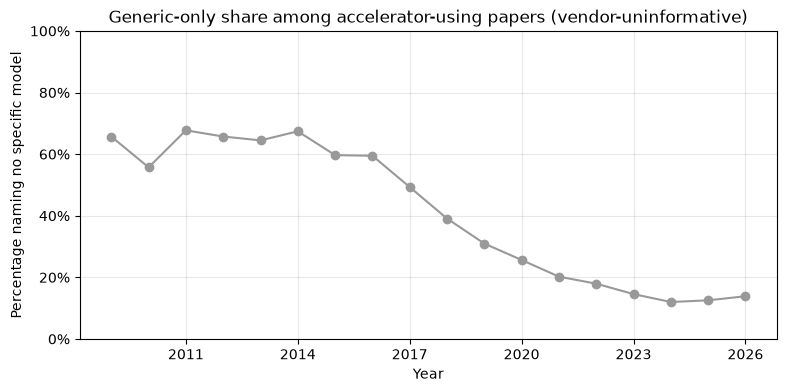

shape: (18, 3)
┌──────┬───────┬──────────────┐
│ year ┆ n     ┆ generic_only │
│ ---  ┆ ---   ┆ ---          │
│ i32  ┆ u32   ┆ f64          │
╞══════╪═══════╪══════════════╡
│ 2009 ┆ 137   ┆ 0.657        │
│ 2010 ┆ 210   ┆ 0.557        │
│ 2011 ┆ 344   ┆ 0.677        │
│ 2012 ┆ 423   ┆ 0.657        │
│ 2013 ┆ 577   ┆ 0.645        │
│ …    ┆ …     ┆ …            │
│ 2022 ┆ 20918 ┆ 0.18         │
│ 2023 ┆ 27871 ┆ 0.146        │
│ 2024 ┆ 41067 ┆ 0.12         │
│ 2025 ┆ 54567 ┆ 0.125        │
│ 2026 ┆ 35375 ┆ 0.139        │
└──────┴───────┴──────────────┘


In [4]:
acc = (flags.join(den, on=KEY, how='inner')
       .filter(pl.col('year').is_between(YEAR_MIN, YEAR_MAX) & pl.col('accel_used')))
gs = (acc.group_by('year').agg(n=pl.len(),
                               generic_only=pl.col('generic_only').mean())
      .filter(pl.col('n') >= MIN_PAPERS).sort('year'))
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(gs['year'], 100 * gs['generic_only'], marker='o', color='#999999')
ax.set(xlabel='Year', ylabel='Percentage naming no specific model', ylim=(0, 100),
       title='Generic-only share among accelerator-using papers (vendor-uninformative)')
ax.grid(alpha=0.3); plt.show()
print(gs.with_columns(pl.col('generic_only').round(3)))

## 8.1 Manufacturer share over time

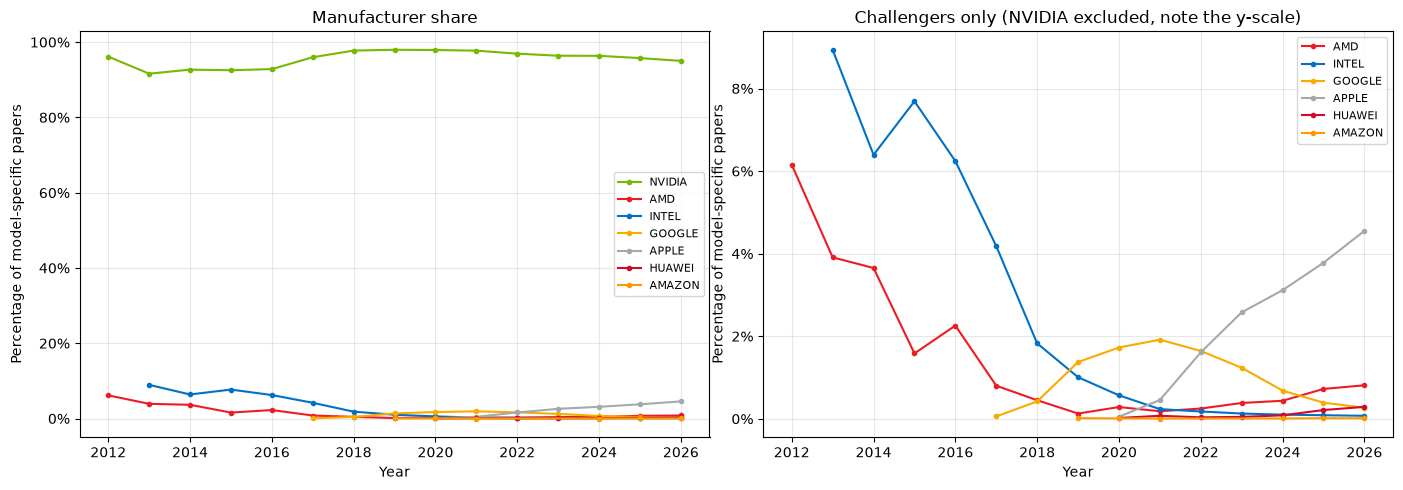

shape: (15, 8)
┌──────┬────────┬────────┬────────┬────────┬────────┬────────┬────────┐
│ year ┆ nvidia ┆ amd    ┆ intel  ┆ google ┆ apple  ┆ huawei ┆ amazon │
│ ---  ┆ ---    ┆ ---    ┆ ---    ┆ ---    ┆ ---    ┆ ---    ┆ ---    │
│ i32  ┆ f64    ┆ f64    ┆ f64    ┆ f64    ┆ f64    ┆ f64    ┆ f64    │
╞══════╪════════╪════════╪════════╪════════╪════════╪════════╪════════╡
│ 2012 ┆ 0.9615 ┆ 0.0615 ┆ null   ┆ null   ┆ null   ┆ null   ┆ null   │
│ 2013 ┆ 0.9162 ┆ 0.0391 ┆ 0.0894 ┆ null   ┆ null   ┆ null   ┆ null   │
│ 2014 ┆ 0.9269 ┆ 0.0365 ┆ 0.0639 ┆ null   ┆ null   ┆ null   ┆ null   │
│ 2015 ┆ 0.9253 ┆ 0.0158 ┆ 0.0769 ┆ null   ┆ null   ┆ null   ┆ null   │
│ 2016 ┆ 0.9283 ┆ 0.0226 ┆ 0.0624 ┆ null   ┆ null   ┆ null   ┆ null   │
│ 2017 ┆ 0.9599 ┆ 0.008  ┆ 0.0418 ┆ 0.0006 ┆ null   ┆ null   ┆ null   │
│ 2018 ┆ 0.9775 ┆ 0.0045 ┆ 0.0183 ┆ 0.0042 ┆ null   ┆ null   ┆ null   │
│ 2019 ┆ 0.9797 ┆ 0.0013 ┆ 0.0101 ┆ 0.0137 ┆ null   ┆ null   ┆ 0.0002 │
│ 2020 ┆ 0.9791 ┆ 0.0028 ┆ 0.0057 ┆ 0.0173 ┆ 0.00

In [5]:
tot = spec.group_by('year').agg(n=pl.col(KEY).n_unique())
vs = (spec.group_by('year', 'vendor').agg(k=pl.col(KEY).n_unique())
      .join(tot, on='year').with_columns(share=pl.col('k') / pl.col('n'))
      .filter(pl.col('n') >= MIN_PAPERS).sort('year'))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for v in VENDORS:
    s = vs.filter(pl.col('vendor') == v)
    if s.height > 2:
        axes[0].plot(s['year'], 100 * s['share'], marker='o', ms=3, label=v.upper(), color=VC[v])
axes[0].set(xlabel='Year', ylabel='Percentage of model-specific papers', title='Manufacturer share')
axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3)
non = vs.filter(pl.col('vendor') != 'nvidia')
for v in [x for x in VENDORS if x != 'nvidia']:
    s = non.filter(pl.col('vendor') == v)
    if s.height > 2:
        axes[1].plot(s['year'], 100 * s['share'], marker='o', ms=3, label=v.upper(), color=VC[v])
axes[1].set(xlabel='Year', ylabel='Percentage of model-specific papers',
            title='Challengers only (NVIDIA excluded, note the y-scale)')
axes[1].legend(fontsize=8); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()
with pl.Config(tbl_rows=25):
    print(vs.pivot(on='vendor', index='year', values='share').sort('year')
          .select(['year'] + [c for c in VENDORS if c in vs['vendor'].unique().to_list()])
          .with_columns(pl.exclude('year').round(4)))

## 8.2 Concentration indices

HHI over manufacturer shares (1 = single vendor) and normalized Shannon entropy
(1 = perfectly even). Computed on paper-level vendor shares within each year.

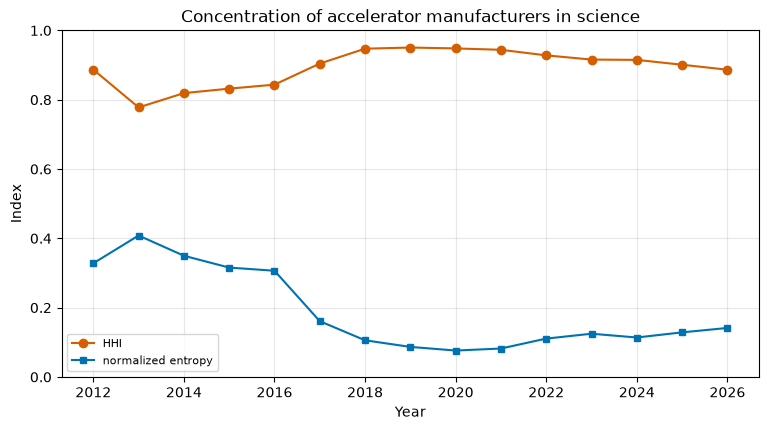

shape: (15, 4)
┌──────┬───────┬─────────┬───────────┐
│ year ┆ hhi   ┆ entropy ┆ n_vendors │
│ ---  ┆ ---   ┆ ---     ┆ ---       │
│ i64  ┆ f64   ┆ f64     ┆ i64       │
╞══════╪═══════╪═════════╪═══════════╡
│ 2012 ┆ 0.887 ┆ 0.328   ┆ 2         │
│ 2013 ┆ 0.778 ┆ 0.408   ┆ 3         │
│ 2014 ┆ 0.819 ┆ 0.35    ┆ 3         │
│ 2015 ┆ 0.832 ┆ 0.316   ┆ 3         │
│ 2016 ┆ 0.844 ┆ 0.306   ┆ 3         │
│ …    ┆ …     ┆ …       ┆ …         │
│ 2022 ┆ 0.928 ┆ 0.111   ┆ 6         │
│ 2023 ┆ 0.916 ┆ 0.125   ┆ 6         │
│ 2024 ┆ 0.915 ┆ 0.114   ┆ 7         │
│ 2025 ┆ 0.901 ┆ 0.129   ┆ 7         │
│ 2026 ┆ 0.887 ┆ 0.141   ┆ 7         │
└──────┴───────┴─────────┴───────────┘


In [6]:
rows = []
for y in sorted(vs['year'].unique().to_list()):
    s = vs.filter(pl.col('year') == y)['share'].to_numpy().astype(float)
    s = s / s.sum()
    ent = -(s * np.log(s)).sum() / np.log(len(s)) if len(s) > 1 else 0.0
    rows.append({'year': y, 'hhi': float((s ** 2).sum()), 'entropy': float(ent),
                 'n_vendors': len(s)})
conc = pl.DataFrame(rows).sort('year')
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(conc['year'], conc['hhi'], marker='o', color='#D55E00', label='HHI')
ax.plot(conc['year'], conc['entropy'], marker='s', ms=4, color='#0072B2',
        label='normalized entropy')
ax.set(xlabel='Year', ylabel='Index', ylim=(0, 1),
       title='Concentration of accelerator manufacturers in science')
ax.legend(fontsize=8); ax.grid(alpha=0.3); plt.show()
print(conc.with_columns(pl.col('hhi').round(3), pl.col('entropy').round(3)))

## 8.3 CUDA lock-in proxy

Share of accelerator-using papers whose candidate passages mention CUDA versus
the portable stacks. Uses the registry's generic entries (`generic-cuda`,
`generic-opencl`) plus a direct pattern sweep for ROCm/HIP/SYCL/oneAPI/Metal,
run over the stored candidate passages — no LLM required.

In [7]:
import re
from accelscan.s3 import list_keys, make_s3_client
import io
client = make_s3_client()
PAT = {
    'cuda': re.compile(r'(?<!\w)(?:CUDA|cuDNN|cuBLAS|nvcc)(?!\w)'),
    'opencl': re.compile(r'(?<!\w)OpenCL(?!\w)', re.IGNORECASE),
    'rocm_hip': re.compile(r'(?<!\w)(?:ROCm|HIP)(?!\w)'),
    'sycl_oneapi': re.compile(r'(?<!\w)(?:SYCL|oneAPI|DPC\+\+)(?!\w)', re.IGNORECASE),
    'metal_mps': re.compile(r'(?<!\w)(?:Metal Performance Shaders|MPS backend)(?!\w)',
                            re.IGNORECASE),
}
prefix = candidates_root(c)
keys = list_keys(prefix, suffix='.parquet', client=client)
cver = sorted({k[len(prefix):].split('/')[0] for k in keys},
              key=lambda v: [int(x) for x in v.split('.')])[-1]
keys = [k for k in keys if k.startswith(f'{prefix}{cver}/')]
print(f'scanning {len(keys)} candidate shards (v{cver})')

acc_ids = set(acc[KEY].to_list())
hits = {k: set() for k in PAT}
seen = set()
for i, k in enumerate(keys):
    body = client.get_object(Bucket=BUCKET, Key=k)['Body'].read()
    df = pl.read_parquet(io.BytesIO(body), columns=[KEY, 'passage_text'])
    for cid, txt in zip(df[KEY].to_list(), df['passage_text'].to_list()):
        if cid not in acc_ids:
            continue
        seen.add(cid)
        if not txt:
            continue
        for name, rx in PAT.items():
            if cid not in hits[name] and rx.search(txt):
                hits[name].add(cid)
    if (i + 1) % 50 == 0 or i + 1 == len(keys):
        print(f'  {i+1}/{len(keys)}')
stack = pl.DataFrame({KEY: sorted(seen)}).with_columns(
    **{f'sw_{n}': pl.col(KEY).is_in(sorted(hits[n])) for n in PAT})
print({n: len(v) for n, v in hits.items()}, '| papers scanned:', len(seen))

scanning 12830 candidate shards (v0.4.0)
  50/12830
  100/12830
  150/12830
  200/12830
  250/12830
  300/12830
  350/12830
  400/12830
  450/12830
  500/12830
  550/12830
  600/12830
  650/12830
  700/12830
  750/12830
  800/12830
  850/12830
  900/12830
  950/12830
  1000/12830
  1050/12830
  1100/12830
  1150/12830
  1200/12830
  1250/12830
  1300/12830
  1350/12830
  1400/12830
  1450/12830
  1500/12830
  1550/12830
  1600/12830
  1650/12830
  1700/12830
  1750/12830
  1800/12830
  1850/12830
  1900/12830
  1950/12830
  2000/12830
  2050/12830
  2100/12830
  2150/12830
  2200/12830
  2250/12830
  2300/12830
  2350/12830
  2400/12830
  2450/12830
  2500/12830
  2550/12830
  2600/12830
  2650/12830
  2700/12830
  2750/12830
  2800/12830
  2850/12830
  2900/12830
  2950/12830
  3000/12830
  3050/12830
  3100/12830
  3150/12830
  3200/12830
  3250/12830
  3300/12830
  3350/12830
  3400/12830
  3450/12830
  3500/12830
  3550/12830
  3600/12830
  3650/12830
  3700/12830
  3750/12830
  38

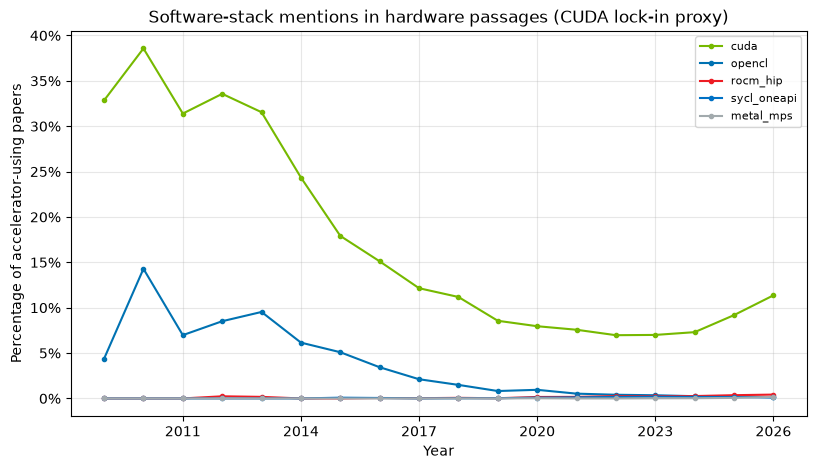

shape: (18, 7)
┌──────┬───────┬────────┬────────┬──────────┬─────────────┬───────────┐
│ year ┆ n     ┆ cuda   ┆ opencl ┆ rocm_hip ┆ sycl_oneapi ┆ metal_mps │
│ ---  ┆ ---   ┆ ---    ┆ ---    ┆ ---      ┆ ---         ┆ ---       │
│ i32  ┆ u32   ┆ f64    ┆ f64    ┆ f64      ┆ f64         ┆ f64       │
╞══════╪═══════╪════════╪════════╪══════════╪═════════════╪═══════════╡
│ 2009 ┆ 137   ┆ 0.3285 ┆ 0.0438 ┆ 0.0      ┆ 0.0         ┆ 0.0       │
│ 2010 ┆ 210   ┆ 0.3857 ┆ 0.1429 ┆ 0.0      ┆ 0.0         ┆ 0.0       │
│ 2011 ┆ 344   ┆ 0.314  ┆ 0.0698 ┆ 0.0      ┆ 0.0         ┆ 0.0       │
│ 2012 ┆ 423   ┆ 0.3357 ┆ 0.0851 ┆ 0.0024   ┆ 0.0         ┆ 0.0       │
│ 2013 ┆ 577   ┆ 0.3154 ┆ 0.0953 ┆ 0.0017   ┆ 0.0         ┆ 0.0       │
│ 2014 ┆ 764   ┆ 0.2435 ┆ 0.0615 ┆ 0.0      ┆ 0.0         ┆ 0.0       │
│ 2015 ┆ 1178  ┆ 0.1791 ┆ 0.0509 ┆ 0.0      ┆ 0.0008      ┆ 0.0       │
│ 2016 ┆ 1979  ┆ 0.1511 ┆ 0.0344 ┆ 0.0005   ┆ 0.0005      ┆ 0.0       │
│ 2017 ┆ 3589  ┆ 0.1215 ┆ 0.0212 ┆ 0.0003   ┆ 0.0

In [8]:
sw = (stack.join(den, on=KEY, how='inner')
      .filter(pl.col('year').is_between(YEAR_MIN, YEAR_MAX)))
sy = (sw.group_by('year').agg(n=pl.len(),
                              **{n: pl.col(f'sw_{n}').mean() for n in PAT})
      .filter(pl.col('n') >= MIN_PAPERS).sort('year'))
fig, ax = plt.subplots(figsize=(9.5, 5))
for n, c in zip(PAT, ['#76B900', '#0072B2', '#ED1C24', '#0071C5', '#A2AAAD']):
    ax.plot(sy['year'], 100 * sy[n], marker='o', ms=3, label=n, color=c)
ax.set(xlabel='Year', ylabel='Percentage of accelerator-using papers',
       title='Software-stack mentions in hardware passages (CUDA lock-in proxy)')
ax.legend(fontsize=8); ax.grid(alpha=0.3); plt.show()
with pl.Config(tbl_rows=20):
    print(sy.with_columns(pl.exclude('year', 'n').round(4)))
print('\nCUDA : portable-stack ratio, recent years:')
print(sy.with_columns(portable=pl.col('opencl') + pl.col('rocm_hip') + pl.col('sycl_oneapi'))
      .with_columns(ratio=(pl.col('cuda') / pl.col('portable')).round(2))
      .select('year', 'cuda', 'portable', 'ratio').tail(8))

## 8.4 Multi-vendor papers

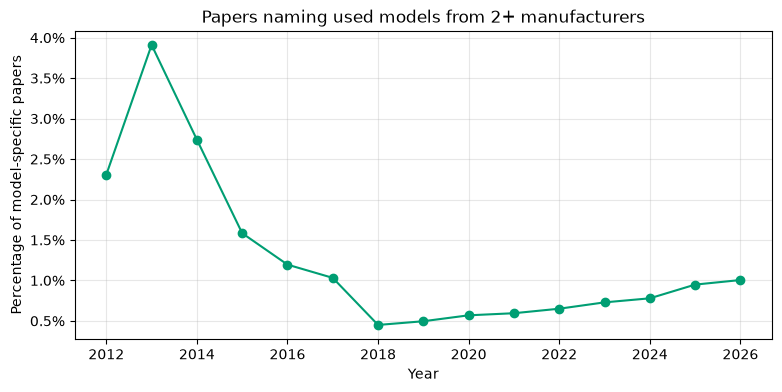

shape: (15, 3)
┌──────┬───────┬────────┐
│ year ┆ n     ┆ multi  │
│ ---  ┆ ---   ┆ ---    │
│ i32  ┆ u32   ┆ f64    │
╞══════╪═══════╪════════╡
│ 2012 ┆ 130   ┆ 0.0231 │
│ 2013 ┆ 179   ┆ 0.0391 │
│ 2014 ┆ 219   ┆ 0.0274 │
│ 2015 ┆ 442   ┆ 0.0158 │
│ 2016 ┆ 753   ┆ 0.012  │
│ …    ┆ …     ┆ …      │
│ 2022 ┆ 16910 ┆ 0.0065 │
│ 2023 ┆ 23463 ┆ 0.0073 │
│ 2024 ┆ 35689 ┆ 0.0078 │
│ 2025 ┆ 47133 ┆ 0.0095 │
│ 2026 ┆ 30053 ┆ 0.01   │
└──────┴───────┴────────┘


In [9]:
mv = (spec.group_by(KEY, 'year').agg(vendors=pl.col('vendor').n_unique())
      .group_by('year').agg(n=pl.len(), multi=(pl.col('vendors') >= 2).mean())
      .filter(pl.col('n') >= MIN_PAPERS).sort('year'))
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(mv['year'], 100 * mv['multi'], marker='o', color='#009E73')
ax.set(xlabel='Year', ylabel='Percentage of model-specific papers',
       title='Papers naming used models from 2+ manufacturers')
ax.grid(alpha=0.3); plt.show()
print(mv.with_columns(pl.col('multi').round(4)))

## 8.5 Export-control sidebar: A800 / H800 / H20

NVIDIA created these parts specifically for the Chinese market in response to
the October 2022 (and tightened October 2023) US export controls. Their
appearance in the literature dates how quickly a trade-policy intervention shows
up at the bench — and they are a clean marker because they exist for no other
reason.

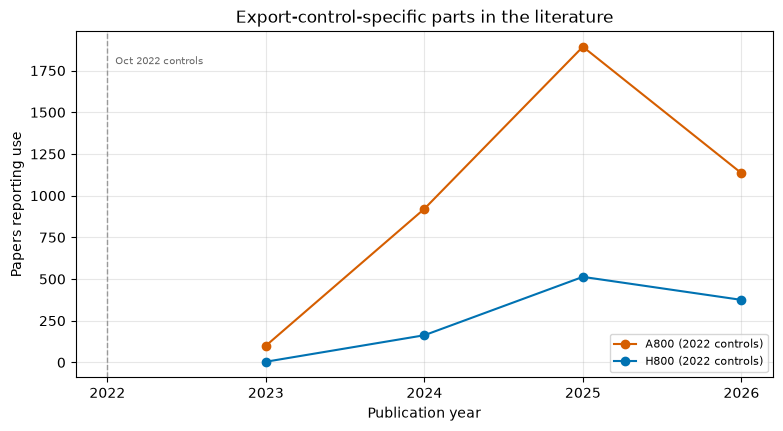

shape: (4, 3)
┌──────┬─────────────┬─────────────┐
│ year ┆ nvidia-h800 ┆ nvidia-a800 │
│ ---  ┆ ---         ┆ ---         │
│ i32  ┆ u32         ┆ u32         │
╞══════╪═════════════╪═════════════╡
│ 2023 ┆ 4           ┆ 100         │
│ 2024 ┆ 163         ┆ 921         │
│ 2025 ┆ 513         ┆ 1893        │
│ 2026 ┆ 375         ┆ 1135        │
└──────┴─────────────┴─────────────┘


In [10]:
CTRL = {'nvidia-a800': 'A800 (2022 controls)', 'nvidia-h800': 'H800 (2022 controls)',
        'nvidia-h20': 'H20 (2023 controls)'}
ctrl = (spec.filter(pl.col('canonical_model').is_in(list(CTRL)))
        .group_by('canonical_model', 'year').agg(k=pl.col(KEY).n_unique())
        .sort('year'))
if ctrl.height:
    fig, ax = plt.subplots(figsize=(9, 4.5))
    for mid, c in zip(CTRL, ['#D55E00', '#0072B2', '#009E73']):
        s = ctrl.filter(pl.col('canonical_model') == mid)
        if s.height:
            ax.plot(s['year'], s['k'], marker='o', label=CTRL[mid], color=c)
    ax.axvline(2022, color='#999999', ls='--', lw=1)
    ax.text(2022.05, ax.get_ylim()[1] * 0.9, 'Oct 2022 controls', fontsize=7, color='#666666')
    ax.set(xlabel='Publication year', ylabel='Papers reporting use',
           title='Export-control-specific parts in the literature')
    ax.legend(fontsize=8); ax.grid(alpha=0.3); plt.show()
    print(ctrl.pivot(on='canonical_model', index='year', values='k').sort('year'))
else:
    print('no export-control parts found in used-model mentions')